# River Water Quality Analysis

Nitrate and oxygen concentrations by season and river section. Concentrations are measured in mg/L. See README.md for test choices, interpretation and limitations.

## Imports

In [1]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import scikit_posthocs as sp

os.makedirs("results", exist_ok=True)

## Load and inspect the data

In [2]:
df = pd.read_csv("waterquality.csv", sep=";")
variables = ["nitrate_mgL", "oxygen_mgL"]
seasons = ["spring", "summer", "autumn", "winter"]
sections = sorted(df["river_section"].unique())
df["saison"] = pd.Categorical(df["saison"], categories=seasons, ordered=True)
df["river_section"] = pd.Categorical(df["river_section"], categories=sections, ordered=True)

print(df.head())
print("\nData types:\n", df.dtypes)
print("\nShape:", df.shape)
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
counts = pd.crosstab(df["river_section"], df["saison"])
print("\nMeasurements by section and season:")
print(counts)
counts.to_csv("results/sample_counts.csv")

   ID  river_section  saison  nitrate_mgL  oxygen_mgL
0   1  A1_headwaters  spring        5.540      10.711
1   2  A1_headwaters  spring        3.328       9.937
2   3  A1_headwaters  spring        5.742      10.499
3   4  A1_headwaters  spring        7.822      10.405
4   5  A1_headwaters  spring        8.843      10.245

Data types:
 ID                  int64
river_section    category
saison           category
nitrate_mgL       float64
oxygen_mgL        float64
dtype: object

Shape: (900, 5)

Missing values:
 ID               0
river_section    0
saison           0
nitrate_mgL      0
oxygen_mgL       0
dtype: int64
Duplicate rows: 0
Duplicate IDs: 0

Measurements by section and season:
saison            spring  summer  autumn  winter
river_section                                   
A1_headwaters         45      45      45      45
A2_upper_course       45      45      45      45
A3_middle_course      45      45      45      45
A4_lower_course       45      45      45      45
A5_mouth 

## Descriptive analysis

In [3]:
summary_names = {"count": "n", "std": "sd", "25%": "Q1", "50%": "median", "75%": "Q3"}
overall = df[variables].describe().T.rename(columns=summary_names)
print("\nOverall summary:")
print(overall)
overall.to_csv("results/descriptive_overall.csv")

by_season = df.groupby("saison", observed=True)[variables].describe()
by_season = by_season.rename(columns=summary_names, level=1)
print("\nSummary by season:")
print(by_season)
by_season.to_csv("results/descriptive_by_season.csv")

by_section = df.groupby("river_section", observed=True)[variables].describe()
by_section = by_section.rename(columns=summary_names, level=1)
print("\nSummary by section:")
print(by_section)
by_section.to_csv("results/descriptive_by_section.csv")

means = df.groupby(["river_section", "saison"], observed=True)[variables].mean().unstack("saison")
print("\nMean concentrations by section and season:")
print(means)
means.to_csv("results/section_season_means.csv")


Overall summary:
                 n      mean        sd    min       Q1  median        Q3  \
nitrate_mgL  900.0  8.811672  2.873274  1.510  6.76225  8.8870  10.92675   
oxygen_mgL   900.0  8.971169  1.425223  4.608  8.05750  9.2635   9.97900   

                max  
nitrate_mgL  16.444  
oxygen_mgL   12.167  

Summary by season:
       nitrate_mgL                                                             \
                 n       mean        sd    min     Q1  median      Q3     max   
saison                                                                          
spring       225.0   9.288844  2.590759  1.510  7.176   9.652  11.215  14.786   
summer       225.0  10.341880  2.744214  3.963  8.357  10.708  12.525  16.444   
autumn       225.0   8.418182  2.752180  1.999  6.627   8.568  10.510  16.377   
winter       225.0   7.197782  2.442061  1.562  5.287   7.552   8.943  13.211   

       oxygen_mgL                                                           
                n     


Mean concentrations by section and season:
                 nitrate_mgL                                 oxygen_mgL  \
saison                spring     summer     autumn    winter     spring   
river_section                                                             
A1_headwaters       5.854444   6.632556   4.920822  3.993756   9.776444   
A2_upper_course     8.008733   8.729489   6.815533  5.817978   9.491133   
A3_middle_course    9.622267  10.954289   8.951889  7.785200   9.477600   
A4_lower_course    11.141244  12.196933  10.141889  8.800111   9.372356   
A5_mouth           11.817533  13.196133  11.260778  9.591867   9.536533   

                                                 
saison              summer    autumn     winter  
river_section                                    
A1_headwaters     7.594356  9.493889  10.058578  
A2_upper_course   7.342867  9.347911   9.838378  
A3_middle_course  7.170244  9.474844   9.835756  
A4_lower_course   6.612022  8.995044   9.795978  
A5_mo

## Boxplots

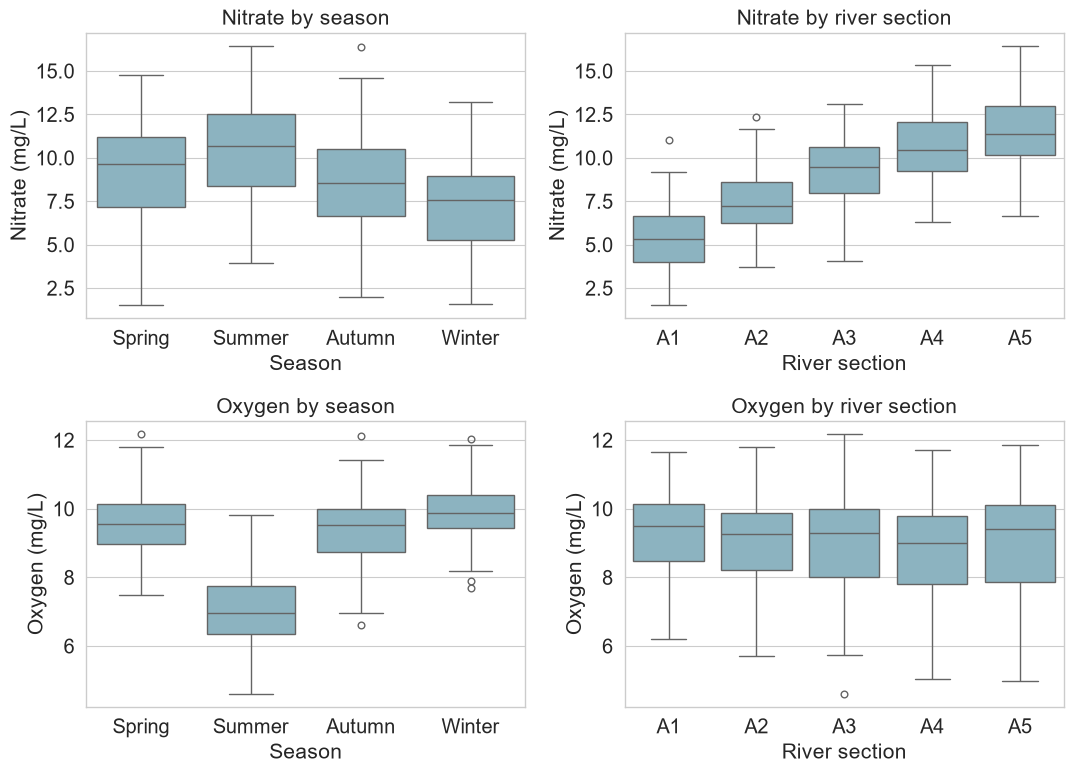

In [4]:
sns.set_theme(style="whitegrid", context="paper", font_scale=1.6)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
sns.boxplot(data=df, x="saison", y="nitrate_mgL", color="#83b8c9", ax=axes[0, 0])
sns.boxplot(data=df, x="river_section", y="nitrate_mgL", color="#83b8c9", ax=axes[0, 1])
sns.boxplot(data=df, x="saison", y="oxygen_mgL", color="#83b8c9", ax=axes[1, 0])
sns.boxplot(data=df, x="river_section", y="oxygen_mgL", color="#83b8c9", ax=axes[1, 1])

axes[0, 0].set(title="Nitrate by season", xlabel="Season", ylabel="Nitrate (mg/L)")
axes[0, 1].set(title="Nitrate by river section", xlabel="River section", ylabel="Nitrate (mg/L)")
axes[1, 0].set(title="Oxygen by season", xlabel="Season", ylabel="Oxygen (mg/L)")
axes[1, 1].set(title="Oxygen by river section", xlabel="River section", ylabel="Oxygen (mg/L)")

# A1 = headwaters, A2 = upper course, A3 = middle course, A4 = lower course, A5 = mouth
section_labels = ["A1", "A2", "A3", "A4", "A5"]
season_labels = ["Spring", "Summer", "Autumn", "Winter"]
axes[0, 0].set_xticks(range(4), season_labels)
axes[1, 0].set_xticks(range(4), season_labels)
axes[0, 1].set_xticks(range(5), section_labels)
axes[1, 1].set_xticks(range(5), section_labels)
fig.tight_layout()
fig.savefig("fig1_boxplots.png", dpi=300, bbox_inches="tight")

## Assumption checks

In [5]:
shapiro_rows = []
levene_rows = []
# RQ1: check spring and autumn separately for each concentration.
for variable in variables:
    spring = df.loc[df["saison"] == "spring", variable]
    autumn = df.loc[df["saison"] == "autumn", variable]
    spring_check = stats.shapiro(spring)
    autumn_check = stats.shapiro(autumn)
    shapiro_rows.append(["RQ1", variable, "spring", len(spring), spring_check.statistic, spring_check.pvalue])
    shapiro_rows.append(["RQ1", variable, "autumn", len(autumn), autumn_check.statistic, autumn_check.pvalue])
    variance_check = stats.levene(spring, autumn, center="median")
    levene_rows.append(["RQ1", variable, variance_check.statistic, variance_check.pvalue])

# RQ2: check all five sections for each concentration.
for variable in variables:
    groups = []
    for section in sections:
        values = df.loc[df["river_section"] == section, variable]
        groups.append(values)
        normality_check = stats.shapiro(values)
        shapiro_rows.append(["RQ2", variable, section, len(values), normality_check.statistic, normality_check.pvalue])
    # The asterisk passes the five groups as separate samples.
    variance_check = stats.levene(*groups, center="median")
    levene_rows.append(["RQ2", variable, variance_check.statistic, variance_check.pvalue])

shapiro = pd.DataFrame(shapiro_rows, columns=["question", "variable", "group", "n", "W", "p_value"])
levene = pd.DataFrame(levene_rows, columns=["question", "variable", "statistic", "p_value"])
print("\nShapiro-Wilk normality checks:")
print(shapiro)
shapiro.to_csv("results/shapiro_wilk.csv", index=False)
print("\nMedian-centred Levene variance checks:")
print(levene)
levene.to_csv("results/levene.csv", index=False)


Shapiro-Wilk normality checks:
   question     variable             group    n         W       p_value
0       RQ1  nitrate_mgL            spring  225  0.985392  2.062424e-02
1       RQ1  nitrate_mgL            autumn  225  0.985027  1.794816e-02
2       RQ1   oxygen_mgL            spring  225  0.994046  5.144426e-01
3       RQ1   oxygen_mgL            autumn  225  0.989181  8.914465e-02
4       RQ2  nitrate_mgL     A1_headwaters  180  0.989597  2.128793e-01
5       RQ2  nitrate_mgL   A2_upper_course  180  0.987795  1.225928e-01
6       RQ2  nitrate_mgL  A3_middle_course  180  0.986516  8.222414e-02
7       RQ2  nitrate_mgL   A4_lower_course  180  0.988149  1.368024e-01
8       RQ2  nitrate_mgL          A5_mouth  180  0.991040  3.245853e-01
9       RQ2   oxygen_mgL     A1_headwaters  180  0.972509  1.261808e-03
10      RQ2   oxygen_mgL   A2_upper_course  180  0.960098  5.373147e-05
11      RQ2   oxygen_mgL  A3_middle_course  180  0.967755  3.552556e-04
12      RQ2   oxygen_mgL   A4_lo

## RQ1: Spring versus autumn

In [6]:
# All differences and effect sizes use spring minus autumn.
# The two primary tests use Bonferroni alpha = 0.05 / 2.
welch_rows = []
for variable in variables:
    spring = df.loc[df["saison"] == "spring", variable]
    autumn = df.loc[df["saison"] == "autumn", variable]
    result = stats.ttest_ind(spring, autumn, equal_var=False)
    ci = result.confidence_interval(confidence_level=0.95)
    n_spring = len(spring)
    n_autumn = len(autumn)
    # Cohen's d: mean difference divided by the pooled standard deviation.
    pooled_sd = np.sqrt(((n_spring - 1) * spring.var(ddof=1) + (n_autumn - 1) * autumn.var(ddof=1)) / (n_spring + n_autumn - 2))
    difference = spring.mean() - autumn.mean()
    cohens_d = difference / pooled_sd
    welch_rows.append({
        "variable": variable,
        "n_spring": n_spring,
        "n_autumn": n_autumn,
        "mean_spring": spring.mean(),
        "mean_autumn": autumn.mean(),
        "mean_difference": difference,
        "difference_ci95_low": ci.low,
        "difference_ci95_high": ci.high,
        "cohens_d": cohens_d,
        "t": result.statistic,
        "df": result.df,
        "p_value": result.pvalue,
        "p_bonferroni": min(2 * result.pvalue, 1.0),
        "reject_at_0.025": result.pvalue < 0.025,
    })

welch = pd.DataFrame(welch_rows)
print("\nSpring versus autumn: Welch t-tests")
print(welch)
welch.to_csv("results/rq1_welch.csv", index=False)


Spring versus autumn: Welch t-tests
      variable  n_spring  n_autumn  mean_spring  mean_autumn  mean_difference  \
0  nitrate_mgL       225       225     9.288844     8.418182         0.870662   
1   oxygen_mgL       225       225     9.530813     9.378876         0.151938   

   difference_ci95_low  difference_ci95_high  cohens_d         t          df  \
0             0.375441              1.365884  0.325763  3.455235  446.373249   
1            -0.009730              0.313606  0.174137  1.846999  447.443333   

    p_value  p_bonferroni  reject_at_0.025  
0  0.000602      0.001205             True  
1  0.065407      0.130815            False  


## RQ2: Nitrate by river section

In [7]:
nitrate_groups = []
for section in sections:
    values = df.loc[df["river_section"] == section, "nitrate_mgL"]
    nitrate_groups.append(values)
anova = stats.f_oneway(*nitrate_groups)
grand_mean = df["nitrate_mgL"].mean()
ss_between = 0
ss_within = 0
for group in nitrate_groups:
    ss_between += len(group) * (group.mean() - grand_mean) ** 2
    ss_within += ((group - group.mean()) ** 2).sum()
eta_squared = ss_between / (ss_between + ss_within)
k = len(sections)
n_total = len(df)
anova_table = pd.DataFrame({
    "source": ["river_section", "within", "total"],
    "sum_sq": [ss_between, ss_within, ss_between + ss_within],
    "df": [k - 1, n_total - k, n_total - 1],
    "mean_sq": [ss_between / (k - 1), ss_within / (n_total - k), np.nan],
    "F": [anova.statistic, np.nan, np.nan],
    "p_value": [anova.pvalue, np.nan, np.nan],
    "eta_squared": [eta_squared, np.nan, np.nan],
}).set_index("source")
print("\nNitrate: one-way ANOVA")
print(anova_table)
anova_table.to_csv("results/rq2_nitrate_anova.csv")

tukey = pairwise_tukeyhsd(df["nitrate_mgL"], df["river_section"], alpha=0.05)
pairs = list(combinations(tukey.groupsunique, 2))
tukey_table = pd.DataFrame({
    "group1": [pair[0] for pair in pairs], "group2": [pair[1] for pair in pairs],
    "mean_difference_group2_minus_group1": tukey.meandiffs,
    "ci95_low": tukey.confint[:, 0], "ci95_high": tukey.confint[:, 1],
    "p_tukey": tukey.pvalues, "reject_at_0.05": tukey.reject,
})
print("\nNitrate: Tukey comparisons")
print(tukey_table)
tukey_table.to_csv("results/rq2_nitrate_tukey.csv", index=False)


Nitrate: one-way ANOVA
                    sum_sq   df      mean_sq           F        p_value  \
source                                                                    
river_section  4418.109583    4  1104.527396  329.103722  4.246425e-174   
within         3003.770397  895     3.356168         NaN            NaN   
total          7421.879980  899          NaN         NaN            NaN   

               eta_squared  
source                      
river_section     0.595282  
within                 NaN  
total                  NaN  



Nitrate: Tukey comparisons
             group1            group2  mean_difference_group2_minus_group1  \
0     A1_headwaters   A2_upper_course                             1.992539   
1     A1_headwaters  A3_middle_course                             3.978017   
2     A1_headwaters   A4_lower_course                             5.219650   
3     A1_headwaters          A5_mouth                             6.116183   
4   A2_upper_course  A3_middle_course                             1.985478   
5   A2_upper_course   A4_lower_course                             3.227111   
6   A2_upper_course          A5_mouth                             4.123644   
7  A3_middle_course   A4_lower_course                             1.241633   
8  A3_middle_course          A5_mouth                             2.138167   
9   A4_lower_course          A5_mouth                             0.896533   

   ci95_low  ci95_high       p_tukey  reject_at_0.05  
0  1.464707   2.520370  1.193490e-13            True  
1  

## RQ2: Oxygen by river section

In [8]:
oxygen_groups = []
for section in sections:
    values = df.loc[df["river_section"] == section, "oxygen_mgL"]
    oxygen_groups.append(values)
kruskal = stats.kruskal(*oxygen_groups)
kruskal_table = pd.DataFrame({"H": [kruskal.statistic], "df": [len(sections) - 1], "p_value": [kruskal.pvalue]})
print("\nOxygen: Kruskal-Wallis test")
print(kruskal_table)
kruskal_table.to_csv("results/rq2_oxygen_kruskal.csv", index=False)

dunn_raw = sp.posthoc_dunn(df, val_col="oxygen_mgL", group_col="river_section", p_adjust=None)
dunn_holm = sp.posthoc_dunn(df, val_col="oxygen_mgL", group_col="river_section", p_adjust="holm")
dunn_rows = []
for group1, group2 in combinations(sections, 2):
    p_value = dunn_raw.loc[group1, group2]
    p_holm = dunn_holm.loc[group1, group2]
    dunn_rows.append([group1, group2, p_value, p_holm, p_holm < 0.05])
dunn_table = pd.DataFrame(dunn_rows, columns=["group1", "group2", "p_value", "p_holm", "reject_at_0.05"])
print("\nOxygen: Dunn comparisons with Holm correction")
print(dunn_table)
dunn_table.to_csv("results/rq2_oxygen_dunn_holm.csv", index=False)


Oxygen: Kruskal-Wallis test
           H  df   p_value
0  11.645113   4  0.020195



Oxygen: Dunn comparisons with Holm correction
             group1            group2   p_value    p_holm  reject_at_0.05
0     A1_headwaters   A2_upper_course  0.117462  0.704771           False
1     A1_headwaters  A3_middle_course  0.145524  0.727619           False
2     A1_headwaters   A4_lower_course  0.000795  0.007946            True
3     A1_headwaters          A5_mouth  0.252538  1.000000           False
4   A2_upper_course  A3_middle_course  0.912417  1.000000           False
5   A2_upper_course   A4_lower_course  0.073591  0.515138           False
6   A2_upper_course          A5_mouth  0.673529  1.000000           False
7  A3_middle_course   A4_lower_course  0.057546  0.460371           False
8  A3_middle_course          A5_mouth  0.755558  1.000000           False
9   A4_lower_course          A5_mouth  0.027073  0.243661           False


## RQ2: Two-way ANOVA with section and season

In [9]:
# Type II sums of squares; partial eta squared = SS_effect / (SS_effect + SS_residual).
effects = ["C(river_section)", "C(saison)", "C(river_section):C(saison)"]
effect_names = ["river_section", "saison", "river_section:saison"]
two_way_rows = []
two_way_checks = []
for variable in variables:
    model = smf.ols(f"{variable} ~ C(river_section) * C(saison)", data=df).fit()
    table = sm.stats.anova_lm(model, typ=2)
    if variable == "oxygen_mgL":
        oxygen_model = model
    ss_residual = table.loc["Residual", "sum_sq"]
    for effect, name in zip(effects, effect_names):
        ss_effect = table.loc[effect, "sum_sq"]
        partial_eta_squared = ss_effect / (ss_effect + ss_residual)
        two_way_rows.append([variable, name, table.loc[effect, "df"], model.df_resid,
                             table.loc[effect, "F"], table.loc[effect, "PR(>F)"], partial_eta_squared])
    # Residual normality and equal variances across the 20 section-season cells.
    cells = []
    for section in sections:
        for season in seasons:
            cells.append(df.loc[(df["river_section"] == section) & (df["saison"] == season), variable])
    normality_check = stats.shapiro(model.resid)
    variance_check = stats.levene(*cells, center="median")
    two_way_checks.append([variable, normality_check.statistic, normality_check.pvalue,
                           variance_check.statistic, variance_check.pvalue])

two_way = pd.DataFrame(two_way_rows, columns=["variable", "effect", "df", "df_error", "F", "p_value",
                                              "partial_eta_squared"])
print("\nTwo-way ANOVA (type II sums of squares):")
print(two_way)
two_way.to_csv("results/rq2_two_way_anova.csv", index=False)

two_way_check_table = pd.DataFrame(two_way_checks, columns=["variable", "shapiro_W", "shapiro_p",
                                                            "levene_statistic", "levene_p"])
print("\nTwo-way ANOVA residual checks:")
print(two_way_check_table)
two_way_check_table.to_csv("results/rq2_two_way_checks.csv", index=False)

# Oxygen: section effect within each season, using the two-way error term.
# Bonferroni alpha = 0.05 / 4 for the four seasons.
mse = oxygen_model.mse_resid
df_error = oxygen_model.df_resid
season_rows = []
for season in seasons:
    season_values = df.loc[df["saison"] == season, "oxygen_mgL"]
    cell_means = df[df["saison"] == season].groupby("river_section", observed=True)["oxygen_mgL"].mean()
    ss_section = 45 * ((cell_means - season_values.mean()) ** 2).sum()
    f_value = (ss_section / (k - 1)) / mse
    p_value = stats.f.sf(f_value, k - 1, df_error)
    season_rows.append([season, f_value, k - 1, df_error, p_value, p_value < 0.05 / 4])
section_by_season = pd.DataFrame(season_rows, columns=["season", "F", "df", "df_error", "p_value",
                                                       "reject_at_0.0125"])
print("\nOxygen: section effect within each season")
print(section_by_season)
section_by_season.to_csv("results/rq2_oxygen_section_by_season.csv", index=False)


Two-way ANOVA (type II sums of squares):
      variable                effect    df  df_error           F  \
0  nitrate_mgL         river_section   4.0     880.0  544.834238   
1  nitrate_mgL                saison   3.0     880.0  197.138206   
2  nitrate_mgL  river_section:saison  12.0     880.0    0.855509   
3   oxygen_mgL         river_section   4.0     880.0    9.519383   
4   oxygen_mgL                saison   3.0     880.0  554.258050   
5   oxygen_mgL  river_section:saison  12.0     880.0    3.896729   

         p_value  partial_eta_squared  
0  2.476802e-236             0.712356  
1   8.837051e-98             0.401936  
2   5.927639e-01             0.011532  
3   1.548348e-07             0.041475  
4  3.307680e-202             0.653921  
5   7.457119e-06             0.050456  

Two-way ANOVA residual checks:
      variable  shapiro_W  shapiro_p  levene_statistic  levene_p
0  nitrate_mgL   0.998853   0.849851          0.720071  0.800507
1   oxygen_mgL   0.999082   0.943337   

## Nitrate ANOVA model checks

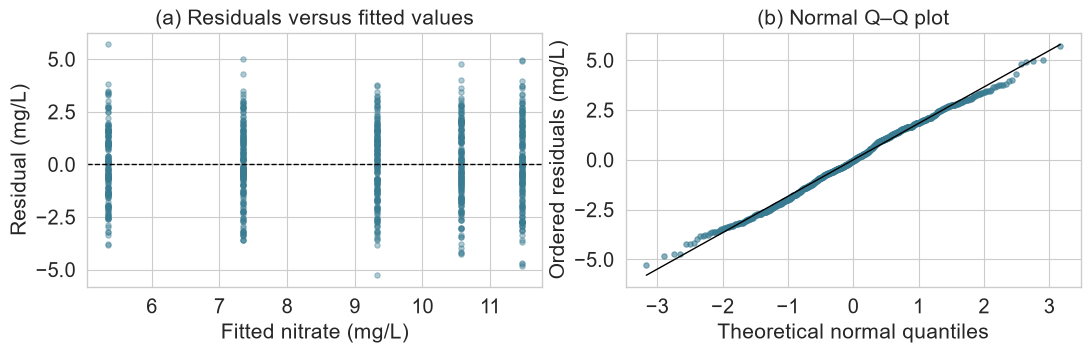

In [10]:
# In one-way ANOVA, each fitted value is its section's sample mean.
fitted = df.groupby("river_section", observed=True)["nitrate_mgL"].transform("mean")
residuals = df["nitrate_mgL"] - fitted

sns.set_theme(style="whitegrid", context="paper", font_scale=1.6)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(fitted, residuals, color="#397b91", alpha=0.4, s=15)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title="(a) Residuals versus fitted values", xlabel="Fitted nitrate (mg/L)",
            ylabel="Residual (mg/L)")

# probplot returns the normal quantiles, the ordered residuals and a fitted reference line.
(quantiles, ordered), (slope, intercept, r) = stats.probplot(residuals, dist="norm")
axes[1].scatter(quantiles, ordered, color="#397b91", alpha=0.6, s=15)
axes[1].plot(quantiles, intercept + slope * quantiles, color="black", linewidth=1)
axes[1].set(title="(b) Normal Q–Q plot", xlabel="Theoretical normal quantiles",
            ylabel="Ordered residuals (mg/L)")
fig.tight_layout()
fig.savefig("fig2_nitrate_anova_diagnostics.png", dpi=300, bbox_inches="tight")